In [33]:
import os
import sys
sys.path.append('../')
from pathlib import Path
import re
import numpy as np
from scipy.io import loadmat
import pandas as pd
import matplotlib.pyplot as plt

# my inference model modules
from latentEnthalpyModel import latentEnthalpyModel, BasalEvidence, PosteriorConfig
from Simulation import Simulation
from lowRankGPPrior import lowRankGPPrior
from enthalpyPosterior import enthalpyPosterior
from posteriorObjective import posteriorObjective


# Preparing data: Load ISSM simulation data

In [ ]:
sim_path = "/data-archive/petermann-thermal-models/sim-ensemble/"
# Find files and extract the ensemble index from each filename.
files = list(Path(sim_path).glob("Eb_GHF_*.mat"))

def ensemble_index(path):
    return int(re.fullmatch(r"Eb_GHF_(\d+)\.mat", path.name).group(1))

files.sort(key=ensemble_index)

if not files:
    raise FileNotFoundError(f"No Eb_GHF_*.mat files found in {sim_path}")

# ensemble[ii] contains the data saved for simulation ii.
ensemble = {}

for file in files:
    ii = ensemble_index(file)
    output = loadmat(file, simplify_cells=True)["output"]

    ensemble[ii] = {
        field: np.asarray(output[field]).reshape(-1)
        for field in ("x_vertex", "y_vertex", "GHF", "Eb")
    }

print(f"Loaded {len(ensemble)} simulations.")

run_ids = np.array(sorted(ensemble))

x_vertex = ensemble[run_ids[0]]["x_vertex"]
y_vertex = ensemble[run_ids[0]]["y_vertex"]


Loaded 500 simulations.
GHF ensemble shape: (500, 14231)
Eb ensemble shape: (500, 14231)


### Pixelate it

In [46]:
from src.prepare_data import pixelate_simulation, read_exp_boundary, pixelate_evidence

# load the domain boundary .exp file
exp_path = (
    "/home/donglaiyang/Documents/Georgia-Tech/Research/"
    "petermann-basin-thermal-model/data/drainage-boundary/"
    "1.1-1.2-downsample-boundary.exp"
)
boundary_xy = read_exp_boundary(exp_path)

pixelated = {
    ii: pixelate_simulation(
        sim,
        nx=256,
        ny=256,
        boundary_xy=boundary_xy,
    )
    for ii, sim in ensemble.items()
}

run_ids = np.array(sorted(pixelated))

GHF_pixels = np.stack([pixelated[ii]["GHF"] for ii in run_ids])
Eb_pixels = np.stack([pixelated[ii]["Eb"] for ii in run_ids])

# Shared mask and grid coordinates.
grid = pixelated[run_ids[0]]
mask = grid["mask"]
x_grid = grid["x"]
y_grid = grid["y"]

print("GHF shape:", GHF_pixels.shape)
print("Eb shape:", Eb_pixels.shape)
print("Mask shape:", mask.shape)

assert np.all(GHF_pixels[:, ~mask] == 0)
assert np.all(Eb_pixels[:, ~mask] == 0)

GHF shape: (500, 256, 256)
Eb shape: (500, 256, 256)
Mask shape: (256, 256)


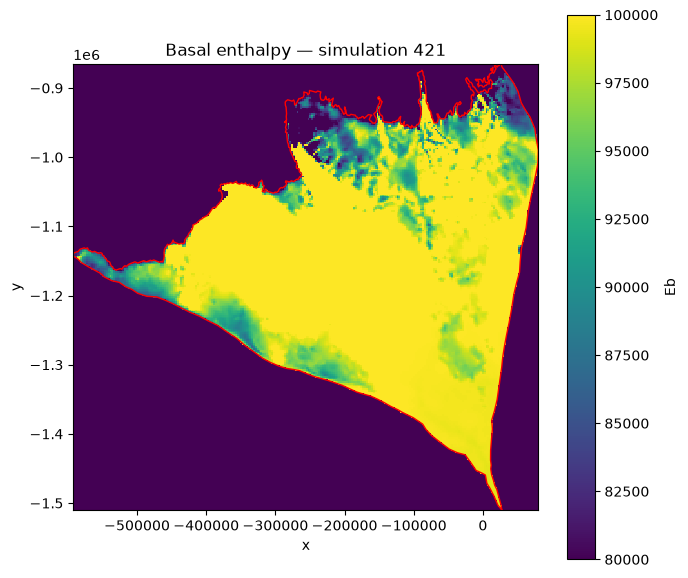

In [31]:
import matplotlib.pyplot as plt

ii = run_ids[420]
grid = pixelated[ii]

fig, ax = plt.subplots(figsize=(7, 6))

image = ax.pcolormesh(
    grid["x_edges"],
    grid["y_edges"],
    grid["Eb"],
    shading="flat",
    cmap="viridis",
    vmin=8e4, vmax=1e5
)

boundary = grid["boundary_xy"]
ax.plot(boundary[:, 0], boundary[:, 1], "r-", linewidth=1)

ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"Basal enthalpy — simulation {ii}")
fig.colorbar(image, ax=ax, label="Eb")

plt.tight_layout()
plt.show()


# Preparing data: Load basal thermal evidence

In [36]:
evidence_path = "../data/evidence/"
thawed_path = evidence_path + "thawed.csv"
frozen_path = evidence_path + "frozen.csv"

# load evidence data
thawed_df = pd.read_csv(thawed_path, skiprows=5)
frozen_df = pd.read_csv(frozen_path, skiprows=5)

# display the first few rows of the dataframes
thawed_df.head()
frozen_df.head()

,Lattitude,Longitude
0,80.511887,-55.899845
1,80.512331,-55.901576
2,80.512664,-55.902871
3,80.514778,-55.911032
4,80.516006,-55.915725


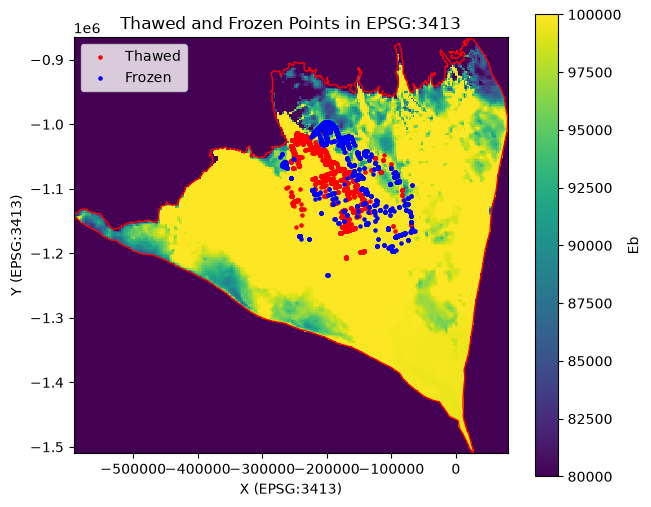

In [45]:
# convert the lat lon to EPSG: 3413
from pyproj import Transformer

thawed_lat = thawed_df['Lattitude'].values
thawed_lon = thawed_df['Longitude'].values
frozen_lat = frozen_df['Lattitude'].values
frozen_lon = frozen_df['Longitude'].values

transformer = Transformer.from_crs("EPSG:4326", "EPSG:3413")
thawed_x, thawed_y = transformer.transform(thawed_lat, thawed_lon)
frozen_x, frozen_y = transformer.transform(frozen_lat, frozen_lon)

# plot them as scattered points 

fig, ax = plt.subplots(figsize=(7, 6))

image = ax.pcolormesh(
    grid["x_edges"],
    grid["y_edges"],
    grid["Eb"],
    shading="flat",
    cmap="viridis",
    vmin=8e4, vmax=1e5
)

boundary = grid["boundary_xy"]
ax.plot(boundary[:, 0], boundary[:, 1], "r-", linewidth=1)

ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"Basal enthalpy — simulation {ii}")
fig.colorbar(image, ax=ax, label="Eb")

ax.scatter(thawed_x, thawed_y, s = 5, color='red', label='Thawed')
ax.scatter(frozen_x, frozen_y, s = 5, color='blue', label='Frozen')
ax.set_xlabel('X (EPSG:3413)')
ax.set_ylabel('Y (EPSG:3413)')
ax.set_title('Thawed and Frozen Points in EPSG:3413')
ax.legend()
plt.show()

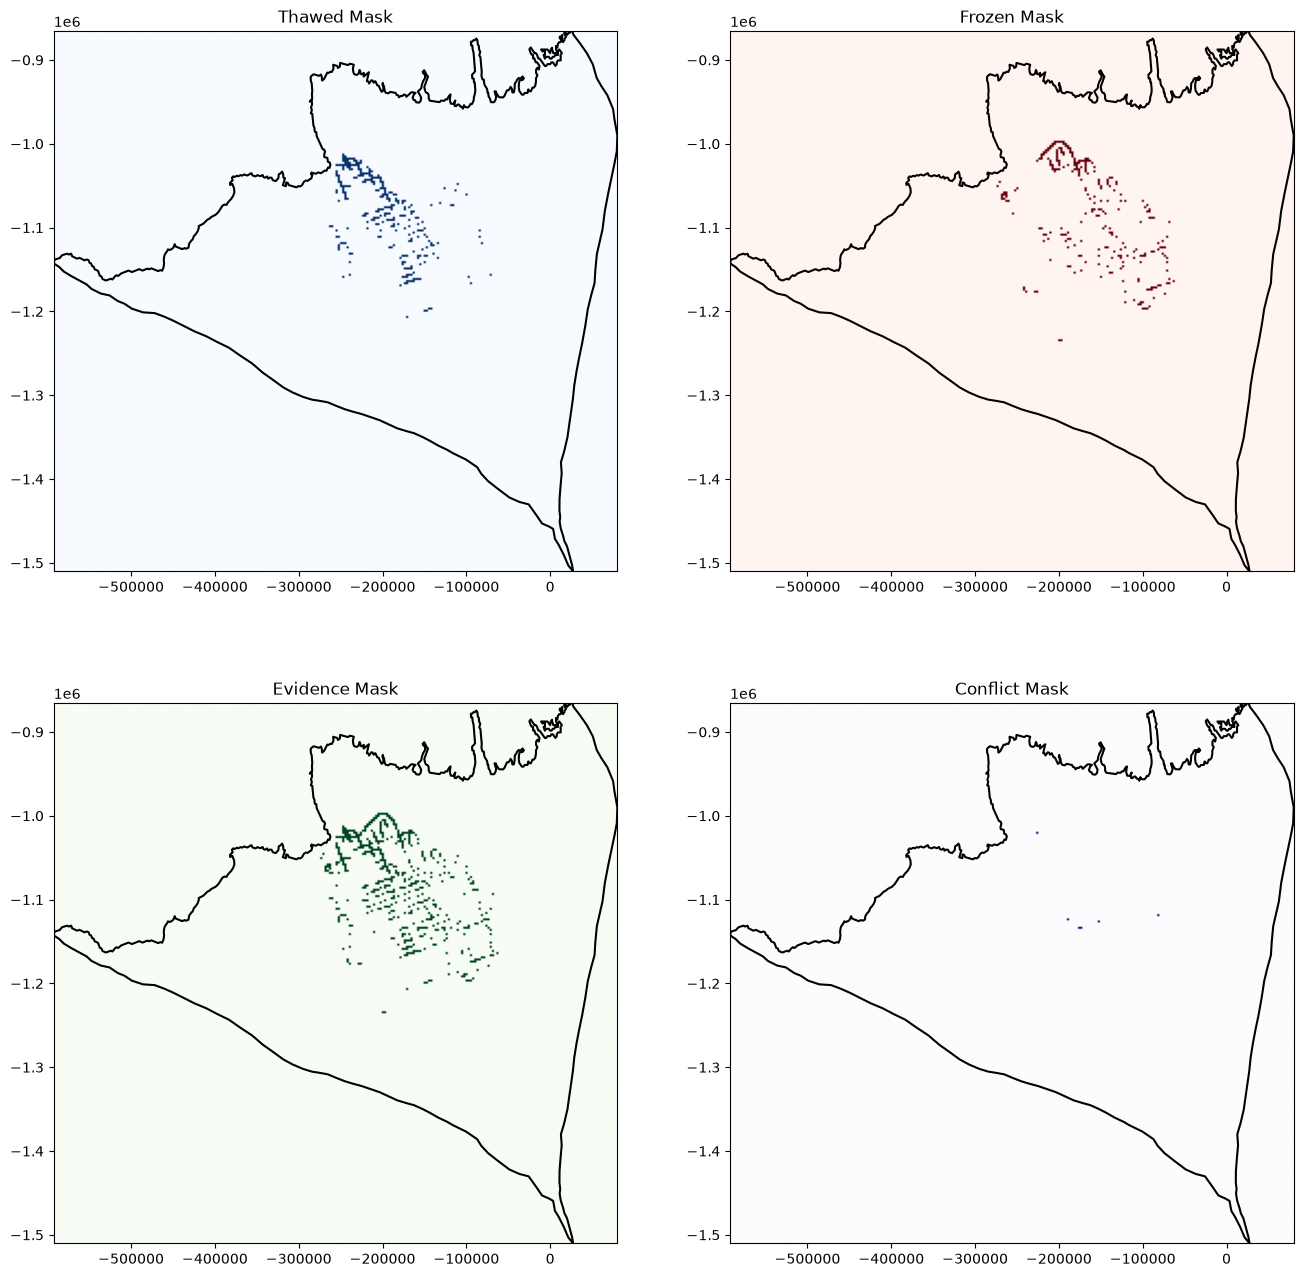

In [52]:
evidence_masks = pixelate_evidence(
    grid,
    thawed_x=thawed_x,
    thawed_y=thawed_y,
    frozen_x=frozen_x,
    frozen_y=frozen_y,
)

# get spatial extent for plotting
extent = [grid["x_edges"][0], grid["x_edges"][-1], grid["y_edges"][0], grid["y_edges"][-1]]

# visualize the masks
plt.figure(figsize=(16, 16))
plt.subplot(2,2,1)
plt.imshow(evidence_masks["thawed_mask"], cmap="Blues", origin="lower", extent=extent)
# add boundary
plt.plot(boundary_xy[:, 0], boundary_xy[:, 1], color="black")
plt.title("Thawed Mask")

plt.subplot(2,2,2)
plt.imshow(evidence_masks["frozen_mask"], cmap="Reds", origin="lower", extent=extent)
plt.plot(boundary_xy[:, 0], boundary_xy[:, 1], color="black")
plt.title("Frozen Mask")

plt.subplot(2,2,3)
plt.imshow(evidence_masks["evidence_mask"], cmap="Greens", origin="lower", extent=extent)
plt.plot(boundary_xy[:, 0], boundary_xy[:, 1], color="black")
plt.title("Evidence Mask")

plt.subplot(2,2,4)
plt.imshow(evidence_masks["conflict_mask"], cmap="Purples", origin="lower", extent=extent)
plt.plot(boundary_xy[:, 0], boundary_xy[:, 1], color="black")
plt.title("Conflict Mask")

plt.show()
